# ECG Signal Analysis and R-Peak Detection

**Course project – Biomedical Engineering**

**Dataset:** MIT-BIH Arrhythmia Database (`mitdb`, PhysioNet)  
**Main tasks:** load an ECG recording, filter the signal, detect R-peaks, calculate RR intervals and simple heart-rate/HRV measures, then compare detected beats with the reference annotations.

## Project aim

In this project, I wanted to practise some basic ECG signal-processing steps and understand how an automatic QRS detector performs on real recordings. I used the WFDB XQRS detector and tested the workflow on a small selection of MIT-BIH records.

This is a student learning project. The analysis is not expected to cover every ECG condition, and the results may be affected by noise, signal quality, lead selection, and detector settings. I have included plots and reference-based checks to help review the results, but some cases may still need closer inspection.

> **Important:** This notebook is for education and signal-processing practice only. It is not a medical device and must not be used to diagnose a patient or guide treatment. The HRV values are exploratory, not clinical measurements.


## 1. Set up the environment

The following cell installs the libraries used in the notebook and imports them.

In [1]:
# Run this cell once in Google Colab if the packages are not installed.
%pip -q install wfdb scipy pandas matplotlib numpy

import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wfdb
from wfdb import processing

from scipy.signal import butter, sosfiltfilt

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

print("Environment ready.")
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("WFDB:", wfdb.__version__)

Environment ready.
NumPy: 2.4.6
Pandas: 2.2.3
WFDB: 4.3.1


## 2. Settings

These settings control which recordings and how much signal will be analysed. I used short segments first so that the notebook is easier to run and review.

In [2]:
DATABASE = "mitdb"
PRIMARY_RECORD = "100"
RECORDS = ["100", "101", "102", "103", "104"]

# Set to None to analyze the full record. 60 seconds keeps the benchmark practical.
DURATION_SECONDS = 60
LOW_CUT_HZ = 0.5
HIGH_CUT_HZ = 40.0
FILTER_ORDER = 3

# WFDB XQRS performs QRS-specific detection and estimates its own thresholds.
MATCH_TOLERANCE_MS = 150.0

# Common beat symbols in the MIT-BIH annotation convention.
# Non-beat annotations such as rhythm changes (+), signal quality (~), and comments are excluded.
BEAT_SYMBOLS = {
    "N", "L", "R", "B", "A", "a", "J", "S", "V", "r",
    "F", "e", "j", "n", "E", "/", "f", "Q", "?"
}

print("Configuration loaded.")

Configuration loaded.


## 3. Functions used in the analysis

I put the repeated steps in functions to keep the main analysis cells easier to follow.

In [3]:
def load_ecg_record(record_name, duration_seconds=None, database=DATABASE):
    """Load a WFDB record and select MLII when available."""
    record = wfdb.rdrecord(record_name, pn_dir=database)
    fs = float(record.fs)

    channel_names = list(record.sig_name or [])
    preferred = next(
        (i for i, name in enumerate(channel_names) if name.upper() == "MLII"),
        0
    )

    signal = record.p_signal[:, preferred].astype(float)
    if duration_seconds is not None:
        n_samples = min(len(signal), int(round(duration_seconds * fs)))
        signal = signal[:n_samples]

    if signal.size < max(20, int(fs)):
        raise ValueError(f"Record {record_name} is too short for reliable filtering.")

    return {
        "record": record,
        "signal": signal,
        "fs": fs,
        "channel_index": preferred,
        "channel_name": channel_names[preferred] if channel_names else f"channel_{preferred}",
        "time": np.arange(signal.size) / fs,
    }


def bandpass_filter(signal, fs, low_hz=LOW_CUT_HZ, high_hz=HIGH_CUT_HZ,
                    order=FILTER_ORDER):
    """Zero-phase Butterworth bandpass filter using second-order sections."""
    nyquist = fs / 2.0
    if not (0 < low_hz < high_hz < nyquist):
        raise ValueError(
            f"Invalid filter limits: require 0 < low < high < Nyquist ({nyquist:.2f} Hz)."
        )
    if not np.all(np.isfinite(signal)):
        raise ValueError("ECG signal contains NaN or infinite values.")

    sos = butter(order, [low_hz, high_hz], btype="bandpass", fs=fs, output="sos")
    # sosfiltfilt requires a minimum signal length; report a clear error if too short.
    return sosfiltfilt(sos, signal)


def detect_r_peaks(filtered_signal, fs):
    """Detect QRS complexes with WFDB's XQRS detector.

    XQRS is designed for ECG QRS detection and is preferable to selecting
    every local amplitude peak. Returned sample indices are sorted and unique.
    """
    signal = np.asarray(filtered_signal, dtype=float)
    if signal.ndim != 1 or signal.size < int(2 * fs):
        raise ValueError("XQRS requires a one-dimensional ECG segment of at least 2 seconds.")
    if not np.all(np.isfinite(signal)):
        raise ValueError("ECG signal contains NaN or infinite values.")

    detected = processing.xqrs_detect(
        sig=signal, fs=float(fs), learn=True, verbose=False
    )
    peaks = np.unique(np.asarray(detected, dtype=int))
    peaks = peaks[(peaks >= 0) & (peaks < signal.size)]
    return peaks, {"detector": "WFDB XQRS"}, np.nan


def get_reference_beats(record_name, n_samples, database=DATABASE):
    """Read reference beat annotations and retain only beat symbols in the segment."""
    annotation = wfdb.rdann(record_name, "atr", pn_dir=database)
    samples = np.asarray(annotation.sample, dtype=int)
    symbols = np.asarray(annotation.symbol, dtype=str)

    keep = np.array([
        (symbol in BEAT_SYMBOLS) and (0 <= sample < n_samples)
        for sample, symbol in zip(samples, symbols)
    ], dtype=bool)
    return np.sort(samples[keep]), annotation


def match_peaks(detected, reference, fs, duration_seconds=None, tolerance_ms=MATCH_TOLERANCE_MS):
    """Chronological one-to-one matching with a fixed tolerance window."""
    detected = np.sort(np.asarray(detected, dtype=int))
    reference = np.sort(np.asarray(reference, dtype=int))
    tolerance = int(round(tolerance_ms * fs / 1000.0))

    i = j = tp = fp = fn = 0
    timing_errors_ms = []

    while i < len(detected) and j < len(reference):
        delta = int(detected[i]) - int(reference[j])
        if abs(delta) <= tolerance:
            tp += 1
            timing_errors_ms.append(abs(delta) * 1000.0 / fs)
            i += 1
            j += 1
        elif delta < -tolerance:
            fp += 1
            i += 1
        else:
            fn += 1
            j += 1

    fp += len(detected) - i
    fn += len(reference) - j

    sensitivity = tp / (tp + fn) if (tp + fn) else np.nan
    precision = tp / (tp + fp) if (tp + fp) else np.nan
    f1 = (
        2 * sensitivity * precision / (sensitivity + precision)
        if np.isfinite(sensitivity) and np.isfinite(precision)
        and (sensitivity + precision) > 0 else np.nan
    )

    return {
        "TP": tp, "FP": fp, "FN": fn,
        "Sensitivity (%)": 100 * sensitivity if np.isfinite(sensitivity) else np.nan,
        "Precision (%)": 100 * precision if np.isfinite(precision) else np.nan,
        "F1 (%)": 100 * f1 if np.isfinite(f1) else np.nan,
        "FP/min": fp / (duration_seconds / 60.0) if duration_seconds and duration_seconds > 0 else np.nan,
        "Mean timing error (ms)": float(np.mean(timing_errors_ms)) if timing_errors_ms else np.nan,
        "Median timing error (ms)": float(np.median(timing_errors_ms)) if timing_errors_ms else np.nan,
    }

print("Helper functions defined.")

Helper functions defined.


In [4]:
# Lightweight software checks for filtering and one-to-one matching.

# Synthetic ECG-like impulses: verifies that XQRS returns valid in-range indices.
_test_fs = 250.0
_test_t = np.arange(10 * int(_test_fs)) / _test_fs
_test_sig = 0.01 * np.sin(2 * np.pi * 1.2 * _test_t)
for _beat_t in np.arange(0.8, 9.2, 1.0):
    _test_sig += np.exp(-0.5 * ((_test_t - _beat_t) / 0.025) ** 2)
_test_filtered = bandpass_filter(_test_sig, _test_fs)
_test_peaks, _, _ = detect_r_peaks(_test_filtered, _test_fs)
assert _test_peaks.ndim == 1 and np.all((_test_peaks >= 0) & (_test_peaks < len(_test_sig)))
_test_metrics = match_peaks(np.array([100, 300]), np.array([102, 500]), fs=250, tolerance_ms=20)
assert (_test_metrics['TP'], _test_metrics['FP'], _test_metrics['FN']) == (1, 1, 1)
print('Software checks passed: filtering, XQRS output bounds, and beat matching.')


Software checks passed: filtering, XQRS output bounds, and beat matching.


## 4. Load the first ECG recording

I start with record 100 and check the selected channel, sampling frequency, and signal length.

Record: 100
Selected channel: MLII
Sampling frequency: 360.00 Hz
Samples analyzed: 21,600
Duration: 60.00 s
Amplitude units: mV


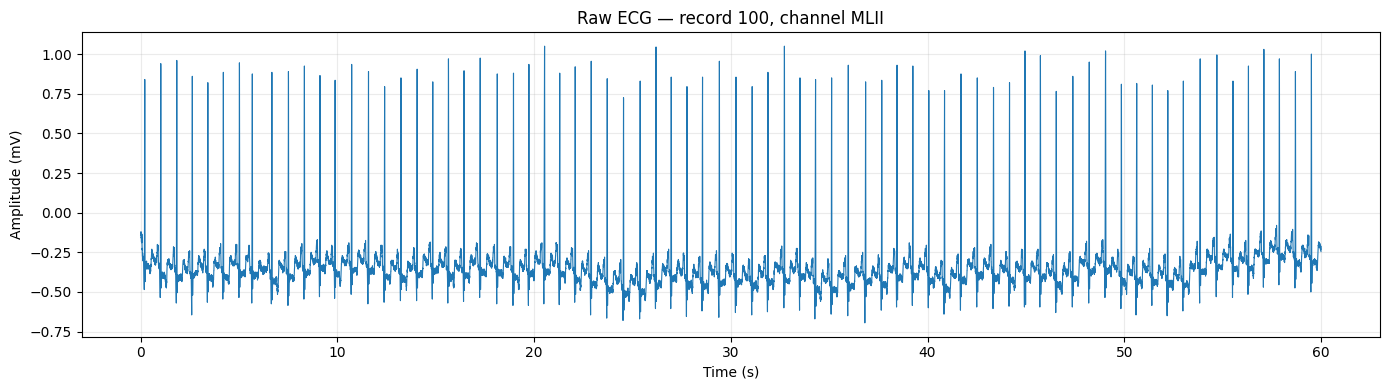

In [5]:
primary = load_ecg_record(PRIMARY_RECORD, DURATION_SECONDS)
ecg_signal = primary["signal"]
fs = primary["fs"]
time = primary["time"]
duration = len(ecg_signal) / fs

print(f"Record: {PRIMARY_RECORD}")
print(f"Selected channel: {primary['channel_name']}")
print(f"Sampling frequency: {fs:.2f} Hz")
print(f"Samples analyzed: {len(ecg_signal):,}")
print(f"Duration: {duration:.2f} s")
print(f"Amplitude units: {primary['record'].units[primary['channel_index']]}")

plt.figure(figsize=(14, 4))
plt.plot(time, ecg_signal, linewidth=0.8)
plt.title(f"Raw ECG — record {PRIMARY_RECORD}, channel {primary['channel_name']}")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude (mV)")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 5. Filter the ECG signal

A band-pass filter is applied to reduce some baseline variation and high-frequency noise. The filtered signal is compared with the original signal.

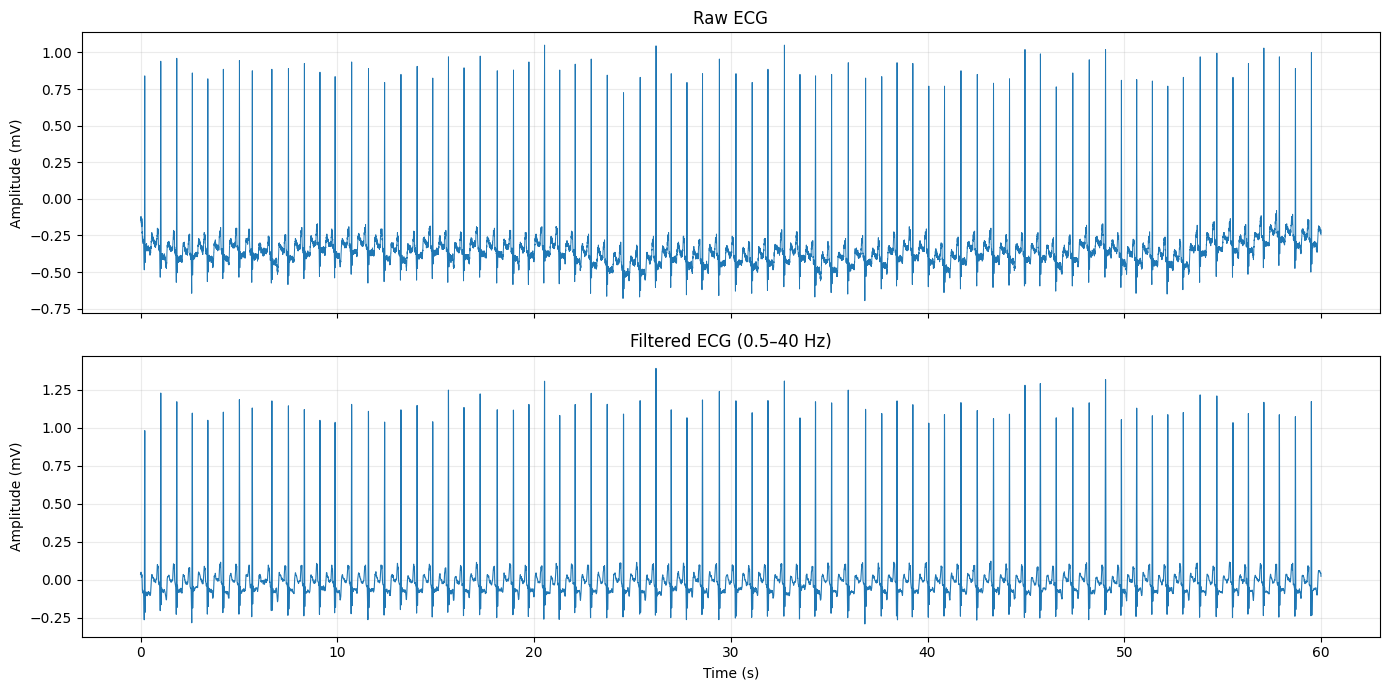

In [6]:
filtered_ecg = bandpass_filter(ecg_signal, fs)

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
axes[0].plot(time, ecg_signal, linewidth=0.7)
axes[0].set_title("Raw ECG")
axes[0].set_ylabel("Amplitude (mV)")
axes[0].grid(alpha=0.25)

axes[1].plot(time, filtered_ecg, linewidth=0.8)
axes[1].set_title(f"Filtered ECG ({LOW_CUT_HZ:g}–{HIGH_CUT_HZ:g} Hz)")
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Amplitude (mV)")
axes[1].grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 6. Detect R-peaks

I use WFDB XQRS to detect the QRS complexes. The plot is useful for checking whether the detected locations appear reasonable.

Detected R-peaks: 74
Detector: WFDB XQRS (adaptive QRS detection)


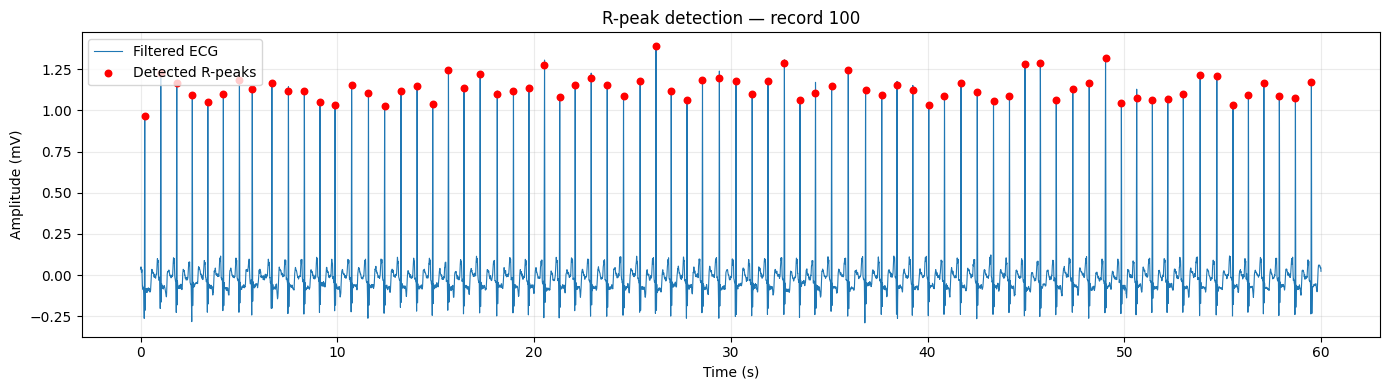

In [7]:
r_peaks, peak_properties, used_prominence = detect_r_peaks(filtered_ecg, fs)

print(f"Detected R-peaks: {len(r_peaks)}")
print("Detector: WFDB XQRS (adaptive QRS detection)")
if len(r_peaks) < 2:
    warnings.warn("Fewer than two peaks were detected; RR and HRV calculations will be limited.")

plt.figure(figsize=(14, 4))
plt.plot(time, filtered_ecg, label="Filtered ECG", linewidth=0.8)
if len(r_peaks):
    plt.scatter(time[r_peaks], filtered_ecg[r_peaks], color="red", s=22, label="Detected R-peaks", zorder=3)
plt.title(f"R-peak detection — record {PRIMARY_RECORD}")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude (mV)")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 7. RR intervals and heart rate

The time difference between consecutive detected R-peaks gives the RR intervals. Instantaneous heart rate is estimated from these intervals.

,Interval #,RR (ms),Heart rate (bpm)
0,1,816.67,73.47
1,2,811.11,73.97
2,3,788.89,76.06
3,4,791.67,75.79
4,5,788.89,76.06
...,...,...,...
68,69,783.33,76.60
69,70,786.11,76.33
70,71,786.11,76.33
71,72,816.67,73.47


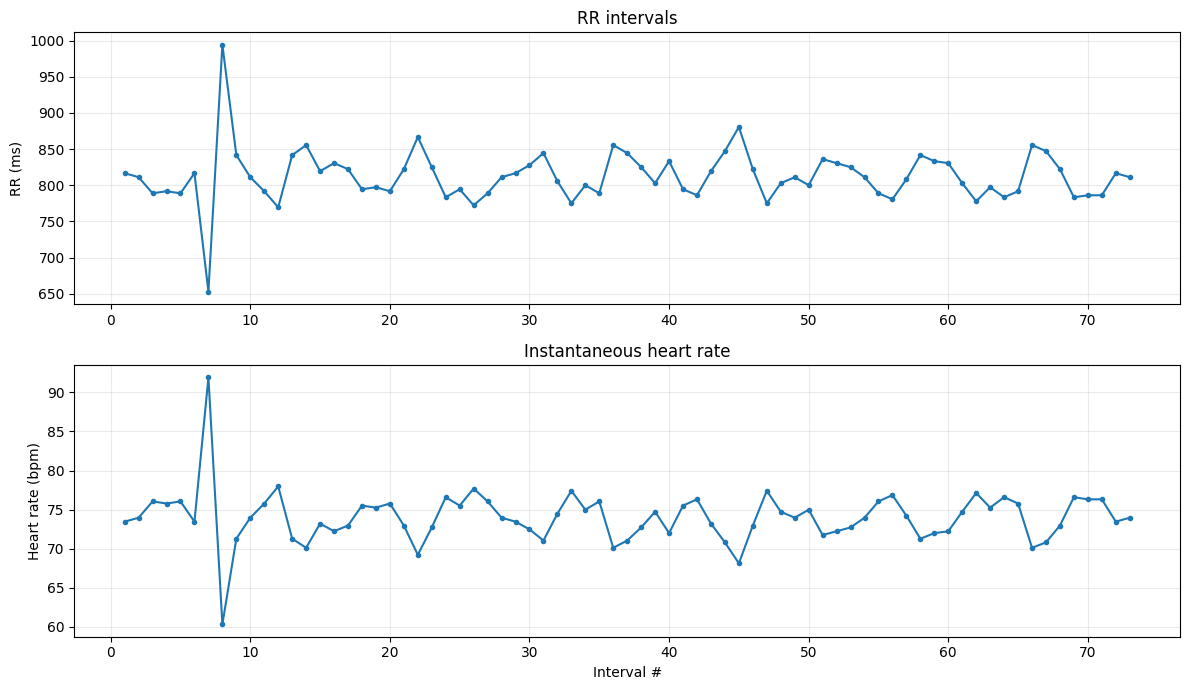

In [8]:
rr_seconds = np.diff(r_peaks) / fs
rr_ms = rr_seconds * 1000.0
instantaneous_hr = 60.0 / rr_seconds if len(rr_seconds) else np.array([])

rr_table = pd.DataFrame({
    "Interval #": np.arange(1, len(rr_ms) + 1),
    "RR (ms)": rr_ms,
    "Heart rate (bpm)": instantaneous_hr
})
display(rr_table.round(2))

if len(rr_ms):
    fig, axes = plt.subplots(2, 1, figsize=(12, 7))
    axes[0].plot(np.arange(1, len(rr_ms) + 1), rr_ms, marker="o", markersize=3)
    axes[0].set_title("RR intervals")
    axes[0].set_ylabel("RR (ms)")
    axes[0].grid(alpha=0.25)

    axes[1].plot(np.arange(1, len(instantaneous_hr) + 1), instantaneous_hr, marker="o", markersize=3)
    axes[1].set_title("Instantaneous heart rate")
    axes[1].set_xlabel("Interval #")
    axes[1].set_ylabel("Heart rate (bpm)")
    axes[1].grid(alpha=0.25)
    plt.tight_layout()
    plt.show()
else:
    print("Not enough detected peaks to calculate RR intervals.")

## 8. Check unusual RR intervals

This is a simple flagging step to help identify intervals that may need visual review. It does not automatically remove any beats.

In [9]:
# Broad plausibility flags for manual review only; no beats are automatically removed.
if len(rr_ms):
    rr_review = pd.DataFrame({
        "Interval #": np.arange(1, len(rr_ms) + 1),
        "RR (ms)": rr_ms,
        "Outside 300–2000 ms": (rr_ms < 300) | (rr_ms > 2000)
    })
    display(rr_review.round(2))
    print("Flagged intervals:", int(rr_review["Outside 300–2000 ms"].sum()))
else:
    print("No RR intervals available for review.")

,Interval #,RR (ms),Outside 300–2000 ms
0,1,816.67,False
1,2,811.11,False
2,3,788.89,False
3,4,791.67,False
4,5,788.89,False
...,...,...,...
68,69,783.33,False
69,70,786.11,False
70,71,786.11,False
71,72,816.67,False


Flagged intervals: 0


## 9. Basic HRV measures

I calculate a few time-domain measures as an introduction to HRV analysis. These values depend on the quality of the detected beats and should be interpreted carefully.

In [10]:
# Metrics are calculated from detected RR intervals as-is.
# They are NOT NN-based clinical HRV metrics unless beats have been appropriately reviewed.
if len(rr_ms) >= 2:
    mean_rr_ms = float(np.mean(rr_ms))
    mean_hr_bpm = float(60000.0 / mean_rr_ms)
    sdnn_ms = float(np.std(rr_ms, ddof=1))
    rmssd_ms = float(np.sqrt(np.mean(np.square(np.diff(rr_ms)))))
    nn50 = int(np.sum(np.abs(np.diff(rr_ms)) > 50.0))
    pnn50 = float(100.0 * nn50 / len(np.diff(rr_ms)))
else:
    mean_rr_ms = float(np.mean(rr_ms)) if len(rr_ms) else np.nan
    mean_hr_bpm = float(60000.0 / mean_rr_ms) if np.isfinite(mean_rr_ms) else np.nan
    sdnn_ms = rmssd_ms = pnn50 = np.nan
    nn50 = 0

hrv_summary = pd.DataFrame([{
    "Mean RR (ms)": mean_rr_ms,
    "Mean HR (bpm)": mean_hr_bpm,
    "SDNN (ms)": sdnn_ms,
    "RMSSD (ms)": rmssd_ms,
    "NN50 count*": nn50,
    "pNN50 (%)": pnn50
}])
display(hrv_summary.round(3))
print("*NN50 label is retained as a conventional interval-difference count; intervals have not been clinically classified as NN.")

,Mean RR (ms),Mean HR (bpm),SDNN (ms),RMSSD (ms),NN50 count*,pNN50 (%)
0,812.291,73.865,37.674,55.289,7,9.722


*NN50 label is retained as a conventional interval-difference count; intervals have not been clinically classified as NN.


## 10. Compare detections with reference annotations

The reference annotations supplied with MIT-BIH are used to estimate how well the detected R-peaks match the annotated beats. The matching tolerance and included beat symbols affect the results.

Reference beat annotations in analyzed segment: 74
Detected peaks: 74


,TP,FP,FN,Sensitivity (%),Precision (%),F1 (%),FP/min,Mean timing error (ms),Median timing error (ms)
0,74,0,0,100.0,100.0,100.0,0.0,0.676,0.0


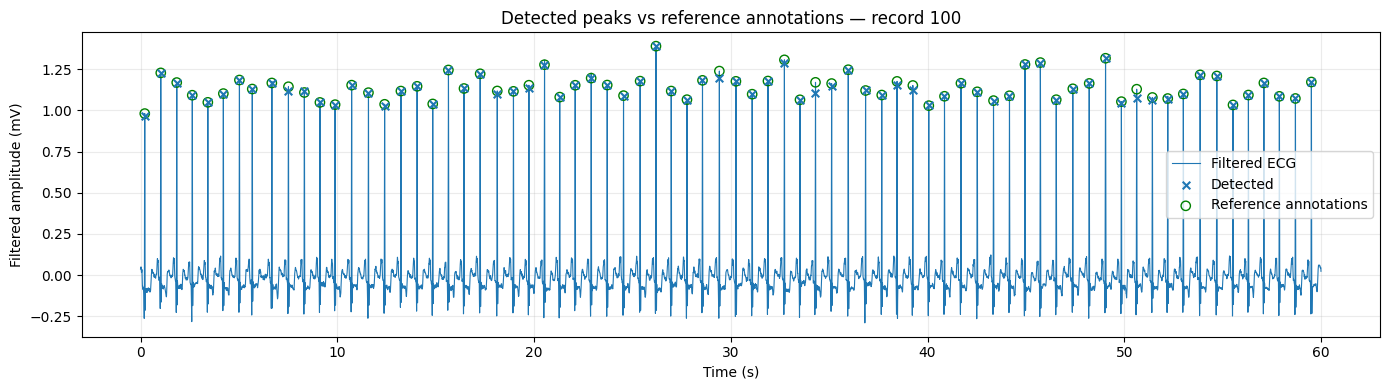

In [11]:
reference_samples, annotation = get_reference_beats(
    PRIMARY_RECORD, len(ecg_signal)
)
primary_metrics = match_peaks(r_peaks, reference_samples, fs, duration_seconds=duration)

print(f"Reference beat annotations in analyzed segment: {len(reference_samples)}")
print(f"Detected peaks: {len(r_peaks)}")
display(pd.DataFrame([primary_metrics]).round(3))

plt.figure(figsize=(14, 4))
plt.plot(time, filtered_ecg, label="Filtered ECG", linewidth=0.8)
if len(r_peaks):
    plt.scatter(time[r_peaks], filtered_ecg[r_peaks], marker="x", s=30, label="Detected", zorder=3)
if len(reference_samples):
    plt.scatter(time[reference_samples], filtered_ecg[reference_samples],
                facecolors="none", edgecolors="green", s=45, label="Reference annotations", zorder=2)
plt.title(f"Detected peaks vs reference annotations — record {PRIMARY_RECORD}")
plt.xlabel("Time (s)")
plt.ylabel("Filtered amplitude (mV)")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 11. Try the workflow on more records

The same steps are repeated for the selected records. This gives a small comparison, rather than a complete evaluation of the MIT-BIH database.

In [12]:
benchmark_rows = []
benchmark_errors = []

for record_name in RECORDS:
    print(f"Processing record {record_name} ...")
    try:
        data = load_ecg_record(record_name, DURATION_SECONDS)
        filtered = bandpass_filter(data["signal"], data["fs"])
        detected, _, prominence = detect_r_peaks(filtered, data["fs"])
        reference, _ = get_reference_beats(record_name, len(data["signal"]))
        metrics = match_peaks(detected, reference, data["fs"], duration_seconds=len(data["signal"]) / data["fs"])

        benchmark_rows.append({
            "Record": record_name,
            "Channel": data["channel_name"],
            "Duration (s)": len(data["signal"]) / data["fs"],
            "Reference beats": len(reference),
            "Detected peaks": len(detected),
            **metrics
        })
    except Exception as exc:
        benchmark_errors.append({"Record": record_name, "Error": str(exc)})
        print(f"  Skipped {record_name}: {exc}")

benchmark_df = pd.DataFrame(benchmark_rows)
if not benchmark_df.empty:
    display(benchmark_df.round(3))
else:
    print("No records were successfully processed.")

if benchmark_errors:
    print("Records with errors:")
    display(pd.DataFrame(benchmark_errors))

Processing record 100 ...
Processing record 101 ...
Processing record 102 ...
Processing record 103 ...
Processing record 104 ...


,Record,Channel,Duration (s),Reference beats,Detected peaks,TP,FP,FN,Sensitivity (%),Precision (%),F1 (%),FP/min,Mean timing error (ms),Median timing error (ms)
0,100,MLII,60.0,74,74,74,0,0,100.000,100.0,100.00,0.0,0.676,0.000
1,101,MLII,60.0,71,71,71,0,0,100.000,100.0,100.00,0.0,0.430,0.000
2,102,V5,60.0,73,73,73,0,0,100.000,100.0,100.00,0.0,3.311,0.000
3,103,MLII,60.0,70,70,70,0,0,100.000,100.0,100.00,0.0,0.317,0.000
4,104,V5,60.0,74,73,73,0,1,98.649,100.0,99.32,0.0,5.289,2.778


## 12. Compare the results

The chart gives a quick view of the detection metrics for the records that were processed successfully.

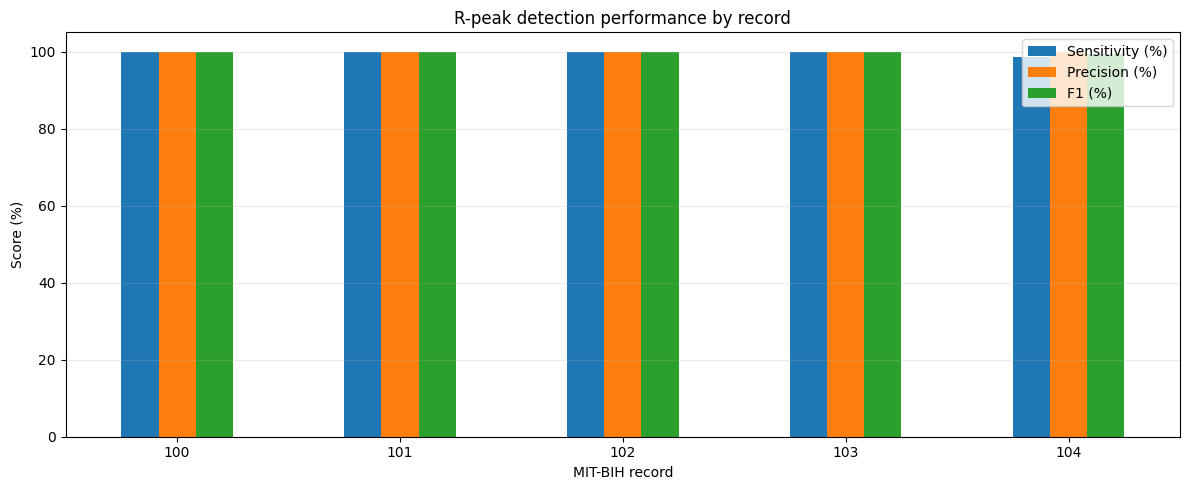

,Sensitivity (%),Precision (%),F1 (%)
mean,99.730,100.0,99.864
std,0.604,0.0,0.304


In [13]:
if not benchmark_df.empty:
    metric_columns = ["Sensitivity (%)", "Precision (%)", "F1 (%)"]
    ax = benchmark_df.set_index("Record")[metric_columns].plot(
        kind="bar", figsize=(12, 5), ylim=(0, 105)
    )
    ax.set_title("R-peak detection performance by record")
    ax.set_ylabel("Score (%)")
    ax.set_xlabel("MIT-BIH record")
    ax.grid(axis="y", alpha=0.25)
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

    display(benchmark_df[metric_columns].agg(["mean", "std"]).round(3))
else:
    print("Benchmark metrics are unavailable.")

## 13. Check that the detector gives repeatable results

I run the detector again on the same signal and compare the peak locations. This checks repeatability for this run; it does not prove that the detections are correct.

In [14]:
# Reproducibility check: rerun XQRS on the primary segment and confirm identical indices.
repeat_peaks, _, _ = detect_r_peaks(filtered_ecg, fs)
reproducibility = {
    "Primary record": PRIMARY_RECORD,
    "First run detections": int(len(r_peaks)),
    "Repeat run detections": int(len(repeat_peaks)),
    "Identical peak locations": bool(np.array_equal(r_peaks, repeat_peaks)),
}
display(pd.DataFrame([reproducibility]))

# Detector parameters are learned by XQRS; no manual threshold sweep is claimed here.
print("XQRS uses its internal learning stage. Inspect the benchmark and overlays for each record.")


,Primary record,First run detections,Repeat run detections,Identical peak locations
0,100,74,74,True


XQRS uses its internal learning stage. Inspect the benchmark and overlays for each record.


## 14. Save the results

The tables are exported as CSV files so they can be reviewed separately or used in a report.

In [15]:
# CSV files are saved in the current Colab working directory.
if not benchmark_df.empty:
    benchmark_df.to_csv("ecg_benchmark_results.csv", index=False)
    print("Saved: ecg_benchmark_results.csv")

if "experiment_df" in globals() and not experiment_df.empty:
    experiment_df.to_csv("ecg_parameter_experiment.csv", index=False)
    print("Saved: ecg_parameter_experiment.csv")

rr_table.to_csv("ecg_primary_rr_intervals.csv", index=False)
print("Saved: ecg_primary_rr_intervals.csv")

# In Google Colab, uncomment to download files to your device:
# from google.colab import files
# files.download("ecg_benchmark_results.csv")
# files.download("ecg_parameter_experiment.csv")
# files.download("ecg_primary_rr_intervals.csv")

Saved: ecg_benchmark_results.csv
Saved: ecg_primary_rr_intervals.csv


## 15. Discussion, limitations, and what I would improve

This notebook gave me practice with loading ECG data, filtering, detecting R-peaks, calculating RR intervals, and comparing detections with reference annotations. The results should be considered preliminary because the analysis uses only a few records and short signal segments.

Some points I noticed and limitations to keep in mind:

1. **R-peak detection:** WFDB XQRS is useful for this exercise, but it may miss beats or detect extra peaks, especially when the signal is noisy or the beat shape is unusual.
2. **Channel choice:** The notebook selects MLII when it is available. If it is not available, it uses the first ECG channel, which may have a different appearance.
3. **Reference annotations:** The comparison depends on which annotation symbols are included. The selected symbols should be checked before comparing these results with another study.
4. **Matching tolerance:** A detected peak is counted as a match only when it is close enough to a reference annotation. Changing the tolerance can change the reported metrics.
5. **Small dataset sample:** Only the first part of the selected records is analysed. This is not enough to make a general statement about detector performance on the full database.
6. **HRV measures:** The calculated values are based on detected RR intervals. I have not performed full beat classification or artifact correction, so these should not be described as clinical HRV results.
7. **Possible next improvements:** I would like to inspect more records, review difficult detections manually, and compare XQRS with another detector.

**Overall:** The notebook demonstrates a basic ECG analysis workflow and provides some initial results. Further testing and review would be needed before drawing stronger conclusions. It is intended for learning, not clinical use.
